In [1]:
import pandas as pd
import re
import numpy as np

# File processing
from pathlib import Path

# Data viz
import seaborn as sns
import matplotlib.pyplot as plt

# Parameters

## File paths

In [2]:
base_dir = Path("../")
data_dir = base_dir / "raw_data"
parsed_data_dir = base_dir / "parsed_data"
ref_data_dir = Path("../../reference_files/")

## Bedtools

In [3]:
from pybedtools import BedTool
from pybedtools.helpers import cleanup as bedtools_cleanup
from pybedtools.helpers import set_tempdir

#### Bedtools tmpdir

In [4]:
bedtools_tmp = data_dir / "bedtools_tmp"
bedtools_tmp.mkdir(parents=True, exist_ok=True)
set_tempdir(bedtools_tmp)

In [5]:
bedtools_cleanup()

In [6]:
# https://github.com/daler/pybedtools/issues/252
def is_valid_bedtools(a):
    '''Does not work for BedTool from iterable'''
    try:
        ft = a.file_type
        if ft == 'empty':
            print("empty file!")
        else:
            print(f'input is {ft} - OK!')
    except IndexError:
        print('bad input!')

    

# Load

In [7]:
gff_columns = [
    "seqname", 
    "source", 
    "feature", 
    "start", 
    "end", 
    "score", 
    "strand", 
    "frame", 
    "attribute"
] 

### Araport

In [9]:
UPSTREAM_LIMIT = 2500
DOWNSTREAM_LIMIT = 2500


In [10]:
araport_tss_region_collapsed_file = parsed_data_dir / f"araport_tss_five_prime_UTR_region_collapsed_{UPSTREAM_LIMIT}-{DOWNSTREAM_LIMIT}.bed"

araport_tss_region = BedTool(araport_tss_region_collapsed_file)
is_valid_bedtools(araport_tss_region)
len(araport_tss_region)

input is gff - OK!


32749

In [18]:
araport_tss_region.head()

Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	5943	10942	.	-	.	Note=8442;ID=AT1G01020;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	10441	15440	.	-	.	Note=12940;ID=AT1G01030;
 Chr1	Araport11	protein	21019	26018	.	+	.	Note=23518;ID=AT1G01040;
 Chr1	Araport11	protein	30171	35170	.	-	.	Note=32670;ID=AT1G01050;
 Chr1	Araport11	protein	34562	39561	.	-	.	Note=37061;ID=AT1G01060;
 

## Dap-seq

In [13]:
subset = "col"
dapseq_bed_file = parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.bed"
dapseq_bed = BedTool(dapseq_bed_file)
is_valid_bedtools(dapseq_bed)
len(dapseq_bed)

input is bed - OK!


1017976

In [17]:
dapseq_bed.head()

Chr1	0	290	1:0-MYBrelated_tnt.TRP2_col_a
 Chr1	0	189	1:0-MYBrelated_tnt.TBP3_col_a
 Chr1	0	310	1:0-MYBrelated_tnt.TRP1_col
 Chr1	140	274	1:140-MYBrelated_tnt.RVE1_col_a
 Chr1	141	295	1:141-MYBrelated_tnt.LHY1_col_a
 Chr1	142	291	1:142-MYBrelated_tnt.AT3G10113_col_a
 Chr1	153	280	1:153-MYBrelated_tnt.At4g01280_col_a
 Chr1	156	282	1:156-MYBrelated_tnt.EPR1_col
 Chr1	530	689	1:530-MYBrelated_tnt.At1g49010_col_a
 Chr1	779	965	1:779-WRKY_tnt.WRKY22_col
 

## Intersection with TSS "region"

In [14]:
# https://bedtools.readthedocs.io/en/latest/content/tools/intersect.html
# minimum overlap as fraction of A (dapseq): f=1
dapseq_intersection = dapseq_bed.intersect(araport_tss_region, f=1, wo=True)
print(len(dapseq_intersection))
dapseq_intersection.head(3)

1475761
Chr1	1337	1580	1:1337-WRKY_tnt.WRKY28_col_a	Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;	243
 Chr1	1352	1529	1:1352-MYB_tnt.MYB57_col_a	Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;	177
 Chr1	1366	1605	1:1366-WRKY_tnt.WRKY15_col_b	Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;	239
 

In [19]:
df_intersection  = dapseq_intersection.to_dataframe(names=[
    'chrom', 'start', 'end', 'name', # bed
    "seqname", "source", "feature", "gff_start", "gff_end", "score", "strand", "frame", "attributes", # gff
    "overlap"
])

In [20]:
df_intersection[df_intersection['name'] == '1:1337-WRKY_tnt.WRKY28_col_a']

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap
0,Chr1,1337,1580,1:1337-WRKY_tnt.WRKY28_col_a,Chr1,Araport11,protein,1260,6259,.,+,.,Note=3759;ID=AT1G01010;,243


In [21]:
peaks = pd.read_csv( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.tsv", sep="\t", usecols=[4, 10], index_col=0)
peaks.head()

,peak
name,
1:141-MYBrelated_tnt.LHY1_col_a,66
1:8025-MYBrelated_tnt.LHY1_col_a,113
1:16285-MYBrelated_tnt.LHY1_col_a,56
1:44590-MYBrelated_tnt.LHY1_col_a,63
1:66684-MYBrelated_tnt.LHY1_col_a,165


array([[<Axes: title={'center': 'peak'}>]], dtype=object)

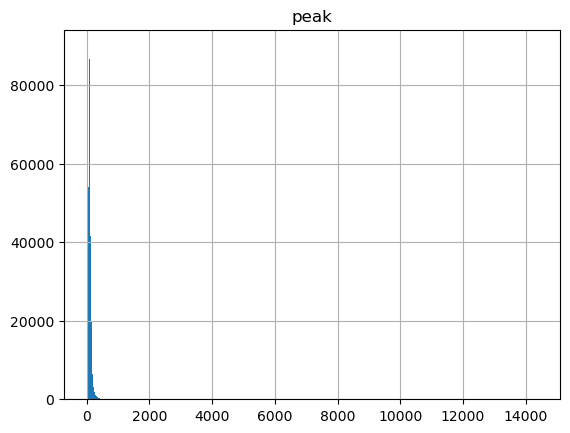

In [14]:
# peaks.hist(bins=2000)

In [22]:
peaks.max()

peak    14374
dtype: int64

In [23]:
peaks[peaks['peak']>2000]

,peak
name,
3:14221640-TCP_tnt.At1g69690_col_a,2764
3:14221660-TCP_tnt.At1g72010_col,2735
1:15099168-MYBrelated_tnt.TRP2_col_a,2857
1:15195711-MYBrelated_tnt.TRP2_col_a,2716
1:15206348-MYBrelated_tnt.TRP2_col_a,2927
3:13589295-WRKY_tnt.WRKY7_col,2366
4:3965603-MYBrelated_tnt.At5g08520_col_b,2739
4:3974767-MYBrelated_tnt.At5g08520_col_b,3080
4:3983505-MYBrelated_tnt.At5g08520_col_b,2630


In [24]:
df_intersection = df_intersection.join(peaks, on="name", how="left")

In [30]:
# df_intersection[df_intersection['name'] == '1:44621-G2like_tnt.At2g01060_col']

In [25]:
len(set(df_intersection["name"]))

829431

In [26]:
df_intersection.shape

(1475761, 15)

In [27]:
df_intersection.groupby("name").size().value_counts()

1     402390
2     276727
3     104877
4      31183
5       9284
6       2723
7       1146
8        489
9        344
10       192
11        66
12        10
Name: count, dtype: int64

In [28]:
def extract_gff_attribute(x, attr="ID"):
    m = re.match(rf".*{attr}=(.*?);", x)
    if m:
        return m.groups()[0]
    else:
        print(x)

In [29]:
df_intersection["target"] = df_intersection["attributes"].apply(extract_gff_attribute, attr="ID")
df_intersection["tss_site"] = df_intersection["attributes"].apply(extract_gff_attribute, attr="Note")
df_intersection["tss_site"] = df_intersection["tss_site"].apply(int)

In [30]:
df_intersection.tail()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap,peak,target,tss_site
1475756,Chr5,26972638,26972780,5:26972638-NAC_tnt.ANAC075_col_a,Chr5,Araport11,protein,26968049,26973048,.,-,.,Note=26970548;ID=AT5G67640;,142,45,AT5G67640,26970548
1475757,Chr5,26972645,26972775,5:26972645-NAC_tnt.ANAC016_col_a,Chr5,Araport11,protein,26968049,26973048,.,-,.,Note=26970548;ID=AT5G67640;,130,47,AT5G67640,26970548
1475758,Chr5,26972648,26972861,5:26972648-bZIP_tnt.TGA6_col_a,Chr5,Araport11,protein,26968049,26973048,.,-,.,Note=26970548;ID=AT5G67640;,213,104,AT5G67640,26970548
1475759,Chr5,26972653,26972803,5:26972653-bZIP_tnt.bZIP68_col_a,Chr5,Araport11,protein,26968049,26973048,.,-,.,Note=26970548;ID=AT5G67640;,150,93,AT5G67640,26970548
1475760,Chr5,26972655,26972790,5:26972655-NAC_tnt.SND2_col_a,Chr5,Araport11,protein,26968049,26973048,.,-,.,Note=26970548;ID=AT5G67640;,135,91,AT5G67640,26970548


## Closest TSS per peak only

__This is done extradinarily inefficiently... __

Closest is not the absolute closest, because the actual closest may not have the peak in its "region". 

Would be waaaay easier of we only did upstream or only downstream (bedtool closest function). 

Or upstream and downstream seperately, and prioritise after?

In [31]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l

In [32]:
df_intersection = df_intersection[
    ['chrom', 'start', 'end', 'name', 
     'seqname', 'strand', 'gff_start',	'gff_end', 
     'overlap', 'target', 'peak', 'tss_site']
]

In [30]:
# df_tss = pd.DataFrame(araport_tss_region.filter(name_filter, l=list(set(df_intersection["target"]))).saveas().to_dataframe()[["start", "end", "attributes"]])
# df_tss.shape

In [31]:
# df_tss.columns = ["tss_start", "tss_end", "ID"]

In [32]:
# df_tss["ID"] = df_tss["ID"].apply(extract_id_gff)

In [33]:
# df_tss.head()

In [34]:
# df_tss[df_tss['ID'] == 'AT1G01070']

In [35]:
# df_intersection[df_intersection['name'] == '1:44621-G2like_tnt.At2g01060_col']

In [36]:
# df_intersection = df_intersection.join(df_tss.set_index("ID"), on="target", how="left")

  -<tss_start>----------/<start>__peak__<end>\-------<tss_end>|protein->
  
 <------|protein<tss_start>-----/<start>__peak__<end>\-------<tss_end>
                    40597          44621    +67     44772        44597


In [33]:
def distance_from_tss(x):

    # start / end  = peak start / peak end
    # gff_start / gff_end  = target region start / target region end   
    
    
    strand = x["strand"]
    tss_site = x["tss_site"]

    if (strand == "+") or (strand == "."):
        # tss_site = x["gff_end"] - DOWNSTREAM_LIMIT
        peak = x["start"] + x["peak"]
        return peak - tss_site
    
    elif strand == "-":
        # tss_site = x["gff_start"] + DOWNSTREAM_LIMIT
        peak = x["start"] + x["peak"]
        return  tss_site - peak 

    else:
        print("strand", strand)
        return pd.NA

    ##################################
    # strand = x["strand"]
    # tss_site = x["tss_site"]
    # # if (strand == "+") or (strand == "."):
    # #     tss_site = x["gff_end"] - DOWNSTREAM_LIMIT
    
    # # elif strand == "-":
    # #     tss_site = x["gff_start"] + DOWNSTREAM_LIMIT

    # overlaps
    # if x["start"] <= tss_site <= x["end"]:
    #     return pd.NA
    
    # if strand == "+" or strand == ".":
        
    #     # peak is upstream, take tss - peak_end
    #     if x["end"] < tss_site:
    #         return x["end"] - tss_site
        
    #     # peak is downstream, take peak_start - tss
    #     elif x["start"] > tss_site:
    #         return x["start"] - tss_site

    #     # shouldn be here
    #     else:
    #         return pd.NA

    # else:
        
    #     # peak is downstream, take tss - peak_end
    #     if x["end"] < tss_site:
    #         return tss_site - x["end"]
        
    #     # peak is upstream, take peak_start - tss
    #     elif x["start"] > tss_site:
    #         return tss_site - x["start"]

    #     # shouldn be here
    #     else:
    #         return pd.NA


In [34]:
df_intersection["distance"] = df_intersection.apply(distance_from_tss, axis=1)

<Axes: xlabel='distance', ylabel='Count'>

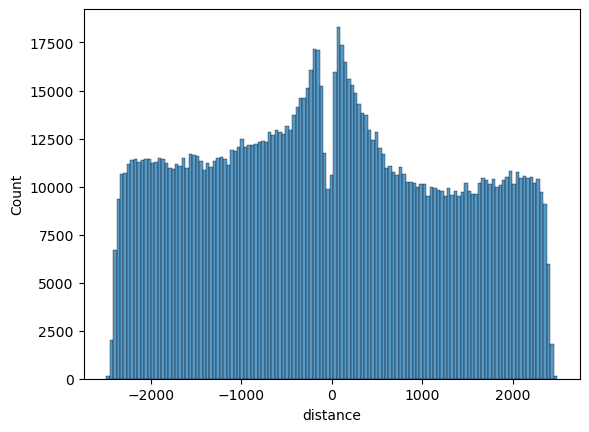

In [35]:
sns.histplot(df_intersection["distance"])

(-1000.0, 1000.0)

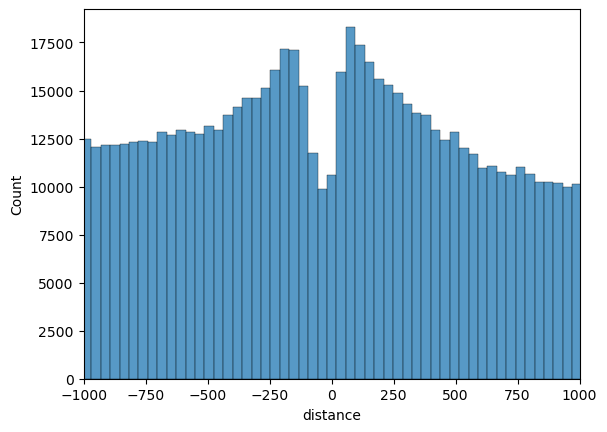

In [36]:
sns.histplot(df_intersection["distance"])
plt.xlim([-1000, 1000])

<Axes: xlabel='distance', ylabel='Count'>

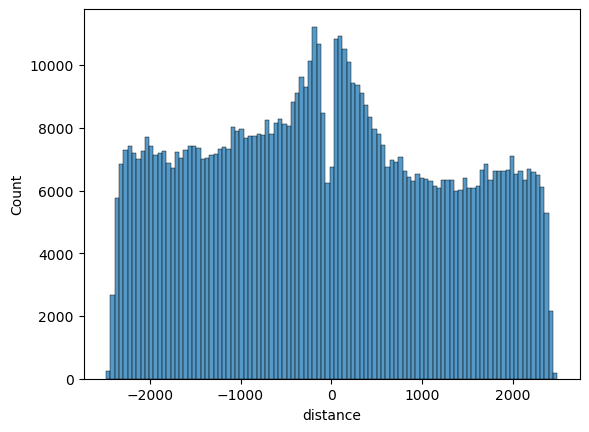

In [37]:
sns.histplot(df_intersection[df_intersection["strand"] == "-"]["distance"])

<Axes: xlabel='distance', ylabel='Count'>

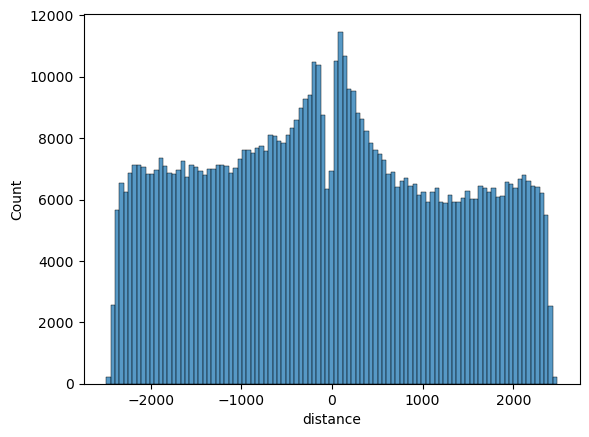

In [38]:
sns.histplot(df_intersection[df_intersection["strand"] != "-"]["distance"])
# plt.xlim([-1000, 1000])

In [44]:
(df_intersection["gff_start"] - df_intersection["gff_end"]).max()

-3523

In [42]:
df_intersection_min_per_peak = df_intersection.loc[df_intersection.groupby('name')['distance'].apply(lambda x: x.abs().idxmin())]

<Axes: xlabel='distance', ylabel='Count'>

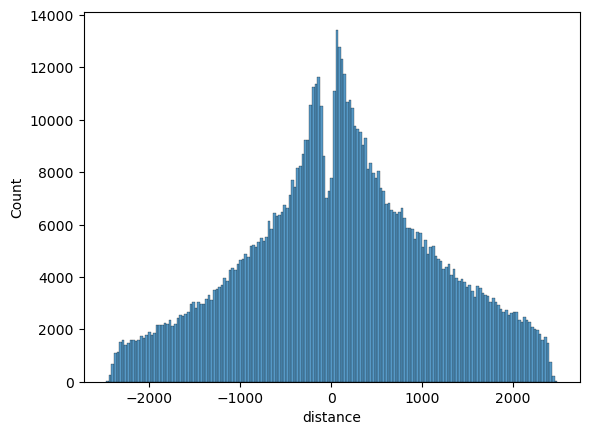

In [43]:
sns.histplot(df_intersection_min_per_peak["distance"])

In [47]:
df_intersection_min_per_peak.shape

(829431, 13)

In [192]:
# def apply_threshold(x, upstream, downstream):
#     return upstream < x < downstream
# df_intersection_min_per_peak_threshold = df_intersection[df_intersection['distance'].apply(apply_threshold, upstream=-2000, downstream=1000)]    
# sns.histplot(df_intersection_min_per_peak_threshold["distance"], stat="percent")
# plt.axvline(0, c="g")
# plt.ylim([0, 1.5])

## Save results

In [48]:
df_intersection_min_per_peak.columns

Index(['chrom', 'start', 'end', 'name', 'seqname', 'strand', 'gff_start',
       'gff_end', 'overlap', 'target', 'peak', 'tss_site', 'distance'],
      dtype='object')

In [51]:
subdf = pd.read_csv( parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.tsv", sep="\t",index_col=0)
subdf.head()

,chrom,chromStart,chromEnd,name,score,strand,signalValue,pValue,qValue,peak,common title,dna source
0,Chr1,141,295,1:141-MYBrelated_tnt.LHY1_col_a,78,.,6.58138,10.19656,7.88710,66,MYBrelated_tnt.LHY1_col_a,col
1,Chr1,8025,8247,1:8025-MYBrelated_tnt.LHY1_col_a,204,.,13.32415,23.72455,20.49854,113,MYBrelated_tnt.LHY1_col_a,col
2,Chr1,16285,16428,1:16285-MYBrelated_tnt.LHY1_col_a,39,.,4.69202,5.94877,3.94847,56,MYBrelated_tnt.LHY1_col_a,col
3,Chr1,44590,44928,1:44590-MYBrelated_tnt.LHY1_col_a,39,.,4.57394,5.94877,3.94847,63,MYBrelated_tnt.LHY1_col_a,col
4,Chr1,66684,66995,1:66684-MYBrelated_tnt.LHY1_col_a,106,.,6.78865,13.19086,10.66210,165,MYBrelated_tnt.LHY1_col_a,col


In [82]:
final_df = df_intersection_min_per_peak[["name", "target", "distance"]].set_index("name").join(
    subdf[['name', 'signalValue', 'pValue', 'qValue', 'common title']].set_index('name'), 
    how="left"
)
final_df.reset_index(inplace=True)
final_df.head()

,name,target,distance,signalValue,pValue,qValue,common title
0,1:1000140-SBP_tnt.SPL9_col_a,AT1G03920,-1292,5.17036,6.47889,4.43642,SBP_tnt.SPL9_col_a
1,1:10001572-TCP_tnt.At1g72010_col,AT1G28450,-2226,8.85368,14.21450,11.65411,TCP_tnt.At1g72010_col
2,1:10001608-NAC_tnt.ANAC034_col,AT1G28450,-2272,11.37872,19.46437,16.68462,NAC_tnt.ANAC034_col
3,1:10002375-MYBrelated_tnt.TBP3_col_a,AT1G28450,-1451,14.54045,26.29065,23.38214,MYBrelated_tnt.TBP3_col_a
4,1:10003294-AP2EREBP_tnt.CBF1_col_a,AT1G28450,-535,38.80624,92.05579,88.62395,AP2EREBP_tnt.CBF1_col_a


In [83]:
SERIES_ACCESSION = "GSE60141"
# sample_metadata_file = parsed_data_dir / f"series_{SERIES_ACCESSION}_sample_metadata.tsv"
peakset_metadata_file = parsed_data_dir / f"series_{SERIES_ACCESSION}_peakset_metadata.tsv"

sample_df = pd.read_csv(sample_metadata_file, sep="\t")#, index_col=12)


sample_df.head()

,gene id,dna source,summary,taxon,protein,protein family,protein affinity tag,expression system,subset,replicate,title,accession,common title
0,AT1G01060,col,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_col_a,GSM1925527,MYBrelated_tnt.LHY1_col_a
1,AT1G01060,colamp,young leaf,Arabidopsis thaliana,LHY1,MYBrelated,Halo,tnt,motif+TFBS,a,MYBrelated_tnt.LHY1_colamp_a,GSM1925526,MYBrelated_tnt.LHY1_colamp_a
2,AT1G01250,col,young leaf,Arabidopsis thaliana,AT1G01250,AP2EREBP,Halo,tnt,motif+TFBS,a,AP2EREBP_tnt.AT1G01250_col_a,GSM1925016,AP2EREBP_tnt.AT1G01250_col_a
3,AT1G01250,colamp,young leaf,Arabidopsis thaliana,AT1G01250,AP2EREBP,Halo,tnt,motif,a,AP2EREBP_tnt.AT1G01250_colamp_a,GSM1925015,AP2EREBP_tnt.AT1G01250_colamp_a
4,AT1G01720,col,young leaf,Arabidopsis thaliana,ATAF1,NAC,Halo,tnt,motif+TFBS,a,NAC_tnt.ATAF1_col_a,GSM1925578,NAC_tnt.ATAF1_col_a


In [84]:
final_df = final_df.join(sample_df.set_index("common title")[['gene id', 'dna source', 'protein',
       'protein family', 'protein affinity tag', 'expression system',
       'accession']], on="common title", how="left") 

In [86]:
final_df.head()

,name,target,distance,signalValue,pValue,qValue,common title,gene id,dna source,protein,protein family,protein affinity tag,expression system,accession
0,1:1000140-SBP_tnt.SPL9_col_a,AT1G03920,-1292,5.17036,6.47889,4.43642,SBP_tnt.SPL9_col_a,AT2G42200,col,SPL9,SBP,Halo,tnt,GSM1925639
1,1:10001572-TCP_tnt.At1g72010_col,AT1G28450,-2226,8.85368,14.21450,11.65411,TCP_tnt.At1g72010_col,AT1G72010,col,At1g72010,TCP,Halo,tnt,"GSM1925892,GSM1925893"
2,1:10001608-NAC_tnt.ANAC034_col,AT1G28450,-2272,11.37872,19.46437,16.68462,NAC_tnt.ANAC034_col,AT2G02450,col,ANAC034,NAC,Halo,tnt,"GSM1925864,GSM1925865"
3,1:10002375-MYBrelated_tnt.TBP3_col_a,AT1G28450,-1451,14.54045,26.29065,23.38214,MYBrelated_tnt.TBP3_col_a,AT5G67580,col,TBP3,MYBrelated,Halo,tnt,GSM1925531
4,1:10003294-AP2EREBP_tnt.CBF1_col_a,AT1G28450,-535,38.80624,92.05579,88.62395,AP2EREBP_tnt.CBF1_col_a,AT4G25490,col,CBF1,AP2EREBP,Halo,tnt,GSM1925055


In [85]:
final_df.columns

Index(['name', 'target', 'distance', 'signalValue', 'pValue', 'qValue',
       'common title', 'gene id', 'dna source', 'protein', 'protein family',
       'protein affinity tag', 'expression system', 'accession'],
      dtype='object')

In [87]:
final_df.columns = ['peak_name', 'target', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'tf', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag',
       'expression system', 'accession']

In [88]:
final_df = final_df[['tf', 'target', 'peak_name', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag', 'expression system', 'accession']]

In [89]:
final_df.head()

,tf,target,peak_name,peak_distance_tss,peak_signalValue,peak_pValue,peak_qValue,library title,dna source,tf protein,tf protein family,protein affinity tag,expression system,accession
0,AT2G42200,AT1G03920,1:1000140-SBP_tnt.SPL9_col_a,-1292,5.17036,6.47889,4.43642,SBP_tnt.SPL9_col_a,col,SPL9,SBP,Halo,tnt,GSM1925639
1,AT1G72010,AT1G28450,1:10001572-TCP_tnt.At1g72010_col,-2226,8.85368,14.21450,11.65411,TCP_tnt.At1g72010_col,col,At1g72010,TCP,Halo,tnt,"GSM1925892,GSM1925893"
2,AT2G02450,AT1G28450,1:10001608-NAC_tnt.ANAC034_col,-2272,11.37872,19.46437,16.68462,NAC_tnt.ANAC034_col,col,ANAC034,NAC,Halo,tnt,"GSM1925864,GSM1925865"
3,AT5G67580,AT1G28450,1:10002375-MYBrelated_tnt.TBP3_col_a,-1451,14.54045,26.29065,23.38214,MYBrelated_tnt.TBP3_col_a,col,TBP3,MYBrelated,Halo,tnt,GSM1925531
4,AT4G25490,AT1G28450,1:10003294-AP2EREBP_tnt.CBF1_col_a,-535,38.80624,92.05579,88.62395,AP2EREBP_tnt.CBF1_col_a,col,CBF1,AP2EREBP,Halo,tnt,GSM1925055


In [90]:
f = parsed_data_dir / f"dapseq_{UPSTREAM_LIMIT}-{DOWNSTREAM_LIMIT}.tsv"
final_df.to_csv(f, sep="\t", index=None)

In [72]:
f

PosixPath('../parsed_data/dapseq_2500-2500.tsv')

In [91]:
!head ../parsed_data/dapseq_2500-2500.tsv

tf	target	peak_name	peak_distance_tss	peak_signalValue	peak_pValue	peak_qValue	library title	dna source	tf protein	tf protein family	protein affinity tag	expression system	accession
AT2G42200	AT1G03920	1:1000140-SBP_tnt.SPL9_col_a	-1292	5.17036	6.47889	4.43642	SBP_tnt.SPL9_col_a	col	SPL9	SBP	Halo	tnt	GSM1925639
AT1G72010	AT1G28450	1:10001572-TCP_tnt.At1g72010_col	-2226	8.85368	14.2145	11.65411	TCP_tnt.At1g72010_col	col	At1g72010	TCP	Halo	tnt	GSM1925892,GSM1925893
AT2G02450	AT1G28450	1:10001608-NAC_tnt.ANAC034_col	-2272	11.37872	19.46437	16.68462	NAC_tnt.ANAC034_col	col	ANAC034	NAC	Halo	tnt	GSM1925864,GSM1925865
AT5G67580	AT1G28450	1:10002375-MYBrelated_tnt.TBP3_col_a	-1451	14.54045	26.29065	23.38214	MYBrelated_tnt.TBP3_col_a	col	TBP3	MYBrelated	Halo	tnt	GSM1925531
AT4G25490	AT1G28450	1:10003294-AP2EREBP_tnt.CBF1_col_a	-535	38.80624	92.05579	88.62395	AP2EREBP_tnt.CBF1_col_a	col	CBF1	AP2EREBP	Halo	tnt	GSM1925055
AT2G23340	AT1G28450	1:10003306-AP2EREBP_tnt.DEAR3_col_a	-555	21.02612	42.101

In [ ]:
# END

<Axes: xlabel='distance', ylabel='Count'>

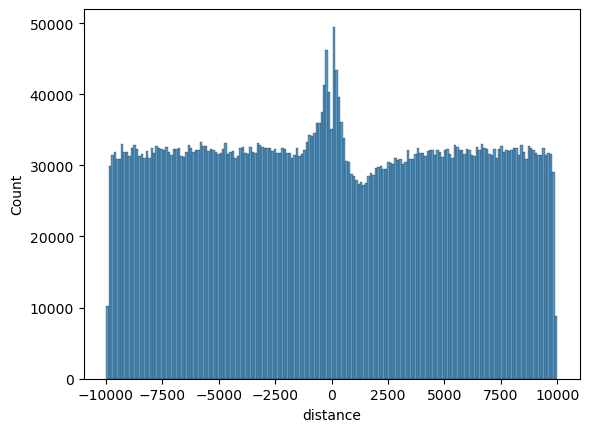

In [40]:
sns.histplot(df_intersection[
    abs(df_intersection["gff_start"] - df_intersection["gff_end"]) == 19999
]["distance"])

<Axes: xlabel='distance', ylabel='Count'>

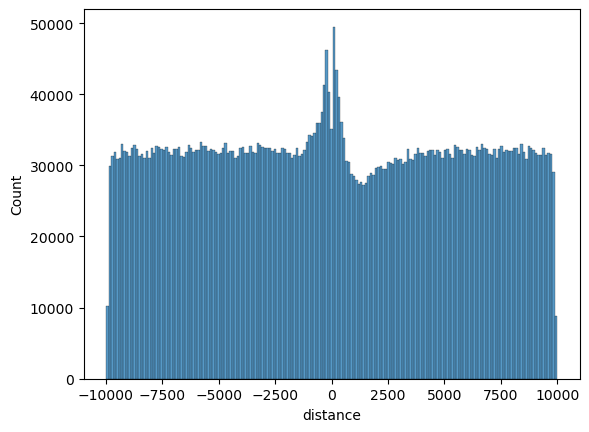

In [61]:
sns.histplot(df_intersection[
    df_intersection["start"] >10000
]["distance"])
# plt.xlim([-1000, 1000])

In [44]:
df_intersection[abs(df_intersection["distance"]) < 1]

,chrom,start,end,name,seqname,strand,gff_start,gff_end,overlap,target,peak,tss_site,distance
25506,Chr1,295108,295398,1:295108-AP2EREBP_tnt.RRTF1_col_a,Chr1,+,285242,305241,290,AT1G01810,133,295241,0
58767,Chr1,669693,669851,1:669693-AP2EREBP_tnt.AT1G12630_col_a,Chr1,-,659774,679773,158,AT1G02960,80,669773,0
64364,Chr1,761240,761422,1:761240-ND_tnt.FRS9_col_a,Chr1,+,751321,771320,182,AT1G03160,80,761320,0
64574,Chr1,766281,766454,1:766281-WRKY_tnt.WRKY71_col_a,Chr1,+,756363,776362,173,AT1G03165,81,766362,0
69828,Chr1,844062,844213,1:844062-WRKY_tnt.WRKY55_col_a,Chr1,-,834159,854158,151,AT1G03400,96,844158,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5752207,Chr5,25809289,25809466,5:25809289-AP2EREBP_tnt.At1g22810_col,Chr5,-,25799396,25819395,177,AT5G64560,106,25809395,0
5764635,Chr5,25967002,25967437,5:25967002-LOBAS2_tnt.LBD18_col_a,Chr5,-,25957308,25977307,435,AT5G65000,305,25967307,0
5779531,Chr5,26186213,26186382,5:26186213-MYB_tnt.MYB93_col_a,Chr5,+,26176316,26196315,169,AT5G65510,102,26186315,0
5817713,Chr5,26672815,26673023,5:26672815-bZIP_tnt.ABF2_col_v3a,Chr5,+,26662926,26682925,208,AT5G66810,110,26672925,0


In [90]:
import math

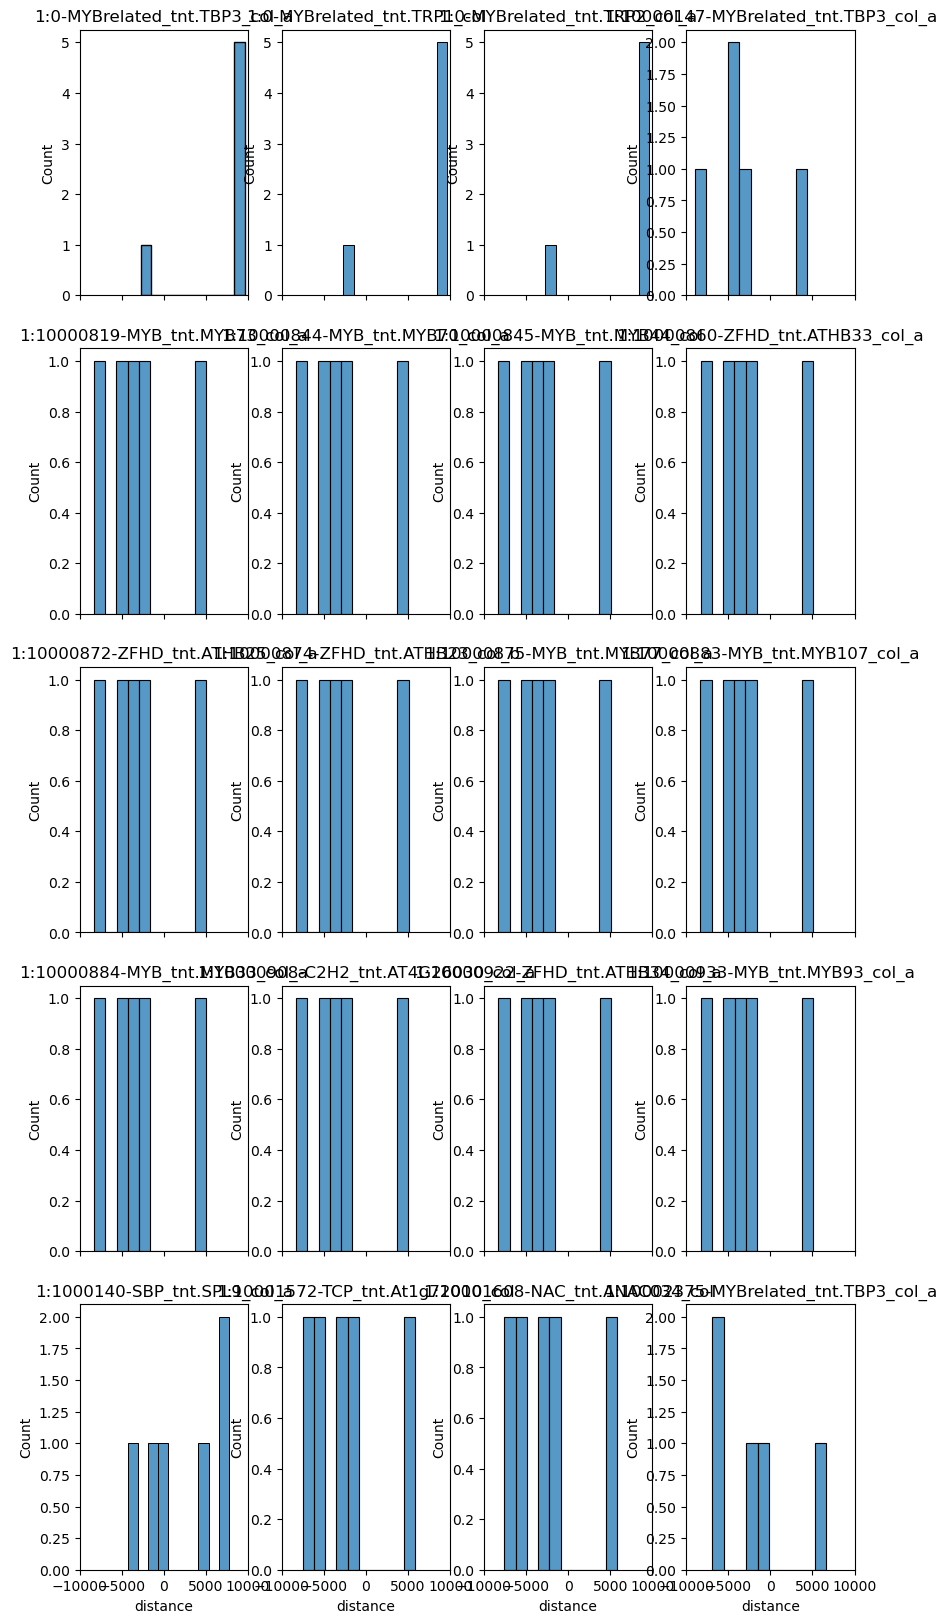

In [98]:
num = 20
ncols = 4

nrows  = math.ceil(num/4)
fig, axes = plt.subplots(ncols=4, nrows=nrows, 
                         figsize=(10, 4*nrows),
                         sharex=True
                        )
axes = axes.flatten()
for i, (tf, df) in enumerate(df_intersection.groupby("name")):
    ax = axes[i]
    sns.histplot(df["distance"], ax=ax, bins=10)
    ax.set_title(tf)
    ax.set_xlim([-10000, 10000])
    i += 1
    
    if i >= num:
        break

chrom    start      end  \
name                                  target                              
1:0-MYBrelated_tnt.TBP3_col_a         AT1G01010  Chr1        0      189   
                                      AT1G01020  Chr1        0      189   
1:0-MYBrelated_tnt.TRP1_col           AT1G01010  Chr1        0      310   
                                      AT1G01020  Chr1        0      310   
1:0-MYBrelated_tnt.TRP2_col_a         AT1G01010  Chr1        0      290   
...                                               ...      ...      ...   
5:9998070-NAC_tnt.SND3_col_b          AT5G27970  Chr5  9998070  9998231   
5:9998571-C2C2dof_tnt.AT1G47655_col_a AT5G27960  Chr5  9998571  9998654   
                                      AT5G27970  Chr5  9998571  9998654   
5:9999664-SBP_tnt.SPL9_col_a          AT5G27960  Chr5  9999664  9999799   
                                      AT5G27970  Chr5  9999664  9999799   

                                                seqname strand  gff_start  \
name                                  target                                
1:0-MYBrelated_tnt.TBP3_col_a         AT1G01010    Chr1      +          1   
                                      AT1G01020    Chr1      -          1   
1:0-MYBrelated_tnt.TRP1_col           AT1G01010    Chr1      +          1   
                                      AT1G01020    Chr1      -          1   
1:0-MYBrelated_tnt.TRP2_col_a         AT1G01010    Chr1      +          1   
...                                                 ...    ...        ...   
5:9998070-NAC_tnt.SND3_col_b          AT5G27970    Chr5      +    9994720   
5:9998571-C2C2dof_tnt.AT1G47655_col_a AT5G27960    Chr5      -    9982771   
                                      AT5G27970    Chr5      +    9994720   
5:9999664-SBP_tnt.SPL9_col_a          AT5G27960    Chr5      -    9982771   
                                      AT5G27970    Chr5      +    9994720   

                                                  gff_end  overlap  peak  \
name                                  target                               
1:0-MYBrelated_tnt.TBP3_col_a         AT1G01010     13759      189    62   
                                      AT1G01020     18666      189    62   
1:0-MYBrelated_tnt.TRP1_col           AT1G01010     13759      310    50   
                                      AT1G01020     18666      310    50   
1:0-MYBrelated_tnt.TRP2_col_a         AT1G01010     13759      290    19   
...                                                   ...      ...   ...   
5:9998070-NAC_tnt.SND3_col_b          AT5G27970  10014719      161    75   
5:9998571-C2C2dof_tnt.AT1G47655_col_a AT5G27960  10002770       83    46   
                                      AT5G27970  10014719       83    46   
5:9999664-SBP_tnt.SPL9_col_a          AT5G27960  10002770      135    81   
                                      AT5G27970  10014719      135    81   

                                                 distance  
name                                  target               
1:0-MYBrelated_tnt.TBP3_col_a         AT1G01010     -3697  
                                      AT1G01020      9939  
1:0-MYBrelated_tnt.TRP1_col           AT1G01010     -3709  
                                      AT1G01020      9951  
1:0-MYBrelated_tnt.TRP2_col_a         AT1G01010     -3740  
...                                                   ...  
5:9998070-NAC_tnt.SND3_col_b          AT5G27970     -6574  
5:9998571-C2C2dof_tnt.AT1G47655_col_a AT5G27960     -5846  
                                      AT5G27970     -6102  
5:9999664-SBP_tnt.SPL9_col_a          AT5G27960     -6974  
                                      AT5G27970     -4974  

[4926325 rows x 10 columns]

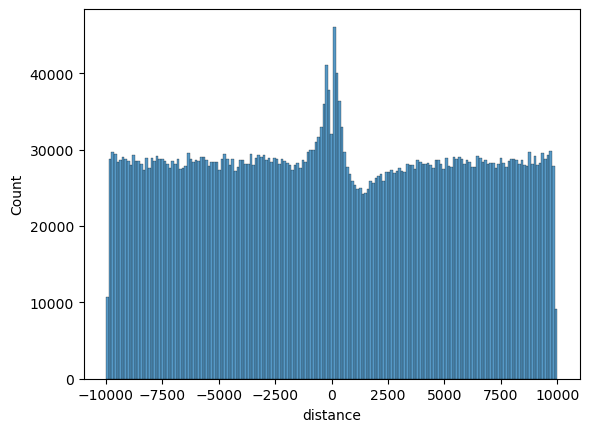

In [74]:
sns.histplot(df_intersection.groupby(["name", "target"]).first()["distance"])

In [98]:
df_intersection[df_intersection["distance"]>4000]

,chrom,start,end,name,seqname,strand,gff_start,gff_end,overlap,target,peak,distance
1,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,-,1,18666,290,AT1G01020,19,9982
2,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,-,1,18419,290,AT1G01020,19,9982
3,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,-,1,18442,290,AT1G01020,19,9982
4,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,-,1,18666,290,AT1G01020,19,9982
6,Chr1,0,189,1:0-MYBrelated_tnt.TBP3_col_a,Chr1,-,1,18666,189,AT1G01020,62,9939
...,...,...,...,...,...,...,...,...,...,...,...,...
5697542,Chr5,26966504,26966662,5:26966504-MYBrelated_tnt.At1g49010_col_a,Chr5,+,26948073,26968072,158,AT5G67590,85,8517
5697549,Chr5,26966723,26966855,5:26966723-TCP_tnt.At1g72010_col,Chr5,+,26948073,26968072,132,AT5G67590,38,8689
5697555,Chr5,26967012,26967215,5:26967012-MYB_tnt.MYB58_col_a,Chr5,+,26948073,26968072,203,AT5G67590,103,9043
5697561,Chr5,26967050,26967233,5:26967050-CAMTA_tnt.CAMTA1_col_a,Chr5,+,26948073,26968072,183,AT5G67590,82,9060


<Axes: xlabel='distance', ylabel='Count'>

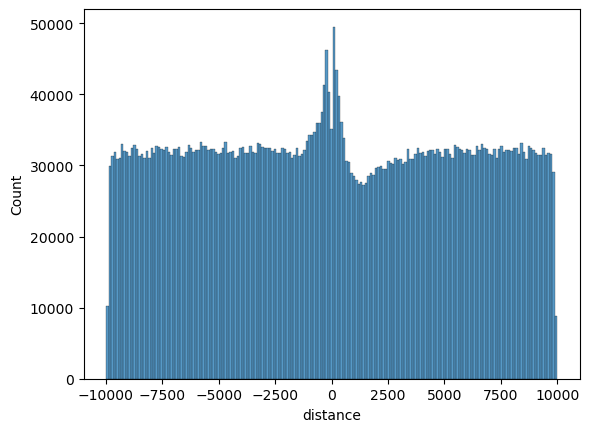

In [45]:
sns.histplot(df_intersection[
    df_intersection["end"] - df_intersection["start"] < 3000
]["distance"])

In [96]:
df_intersection[df_intersection["name"]=="1:15087650-MYBrelated_tnt.TRP1_col"]

,chrom,start,end,name,seqname,strand,gff_start,gff_end,overlap,target,peak,distance


In [241]:
# END

In [65]:
bedtools_cleanup()

In [66]:
araport_file = ref_data_dir / "Araport11_GFF3_genes_transposons.current_utf8_genes.gff.gz"
araport_gff = BedTool(araport_file)
is_valid_bedtools(araport_gff)
araport_gff = araport_gff.sort()
len(araport_gff)

input is gff - OK!


33243

In [67]:
araport_tss = BedTool(generate_tss_intervals(araport_gff))
araport_tss = araport_tss.sort()
araport_tss.head(1)

Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 

In [68]:
araport_tss.TEMPFILES = list(araport_tss.TEMPFILES)

In [73]:
def my_bedtools_cleanup(tmp_dir, keep_files=None):
    if keep_files is None:
        keep_files = []
    else:
        keep_files = [Path(x).name for x in keep_files]

    for f in tmp_dir.glob("pybedtools*"):
        if not (f.name in keep_files):
            f.unlink(missing_ok=True)


In [74]:
my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)

In [75]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l

def get_closest(peak_df, tss=None): 
    list_of_ids = peak_df["target"].to_list()

    if (list_of_ids) == 1:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).absolute_distance(araport_tss.filter(name_filter, l=list_of_ids)):
            result = list_of_ids[0], x
    else:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).closest(
                araport_tss.filter(name_filter, l=list_of_ids), D="b"
            ):
            result = extract_id_gff(x.fields[-2]), x.fields[-1]
    
    global i
    i += 1
    if i % 20 == 0:
        my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)
        
    return pd.Series(result)

In [76]:
i = 0
closest_and_distances = df_intersection.groupby("name").apply(get_closest, tss=araport_tss, include_groups=True)

KeyboardInterrupt: 

In [ ]:
closest_and_distances.columns = ["target", "distance"]
closest_and_distances.to_csv(parsed_data_dir / "tf_target_3000_100.tsv", sep="\t")

In [ ]:
for name, peak_df in df_intersection.head(2000).groupby("name"):
    if peak_df.shape[0] > 1:
        list_of_ids = peak_df["target ID"].to_list()
        break

1:10003433_AP2EREBP_tnt.CBF1_col_a AT1G28450 -346


In [263]:
x.fields

['Chr1',
 '10003333',
 '10003534',
 'AT1G28450',
 'Chr1',
 'Araport11',
 'gene',
 '10003880',
 '10003880',
 '.',
 '+',
 '.',
 'ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-like 58;computational_description=AGAMOUS-like 58;locus=2032543;locus_type=protein_coding;symbol=AGL58;Note=AGAMOUS-like 58;Dbxref=TAIR:2032543;',
 '-346']

In [ ]:
list_of_ids = peak_df["target ID"].to_list()
araport_tss.filter(name_filter, l=list_of_ids).closest()

In [194]:
; list_of_ids

['AT1G28450', 'AT1G28460']

In [195]:
araport_tss.file_type

'gff'

In [168]:
for feature in araport_tss:
    break

In [184]:
feature.attrs.keys()

dict_keys(['ID', 'Name', 'full_name', 'computational_description', 'locus', 'locus_type', 'symbol', 'Note', 'Dbxref'])

In [175]:
feature.attrs["ID"] in list_of_ids

False

<BedTool(/tmp/pybedtools.haemrkev.tmp)>

In [120]:
BedTool(peak_df).closest(araport_tss.filter(lambda x: x.attrs["ID"] in peak_df["target ID"]))

BEDToolsError: 
Command was:

	bedtools closest -b "" -a stdin

Error message was:
Error: Unable to open file . Exiting.


<BedTool(<generator object BedTool.filter.<locals>.<genexpr> at 0x7f8e315c69d0>)>

,start,attributes
0,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
1,9130,ID=AT1G01020;Name=AT1G01020;computational_desc...
2,11101,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...
3,13714,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...
4,23121,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...
...,...,...
33238,321438,ID=ATMG00800;Name=trnE(TTC);Note=None;locus_ty...
33239,321945,ID=ATMG00780;Name=trnS(GCT);Note=None;locus_ty...
33240,330773,ID=ATMG00735;Name=cox3;locus_type=protein_coding
33241,346454,ID=ATMG00700;Name=trnK(TTT);Note=None;locus_ty...


In [70]:
df_intersection.groupby("name").size().value_counts()

1     288945
2     123401
3      26156
4       3698
5        558
6        133
7         59
8         40
9          4
10         2
Name: count, dtype: int64

In [362]:
# dapseq_closest = dapseq_intersection.closest(araport_tss, wo=True, D='b', k=15)

In [363]:
dapseq_closest.head()

Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	201	Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-2111
 Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	20

In [365]:
df_closest  = dapseq_closest.to_dataframe(names=\
    ['chrom', 'start', 'end', 'name'] +\
    [f"{x}_intersection" for x in gff_columns]+\
    ["overlap"] +\
    [f"{x}_closest" for x in gff_columns]+\
    ["distance"]
)
df_closest.shape

ParserError: Error tokenizing data. C error: Expected 24 fields in line 4324271, saw 46


In [366]:
del df_closest

In [ ]:
len(set(df_closest["name"]))

In [358]:
df_closest = df_closest[df_closest["attribute_closest"] == df_closest["attribute_intersection"]]
df_closest.shape

(341211, 24)

In [359]:
df_closest.sort_values('distance', key=abs).groupby('name').first()

,chrom,start,end,seqname_intersection,source_intersection,feature_intersection,gff_start_intersection,gff_end_intersection,score_intersection,strand_intersection,...,seqname_closest,source_closest,feature_closest,gff_start_closest,gff_end_closest,score_closest,strand_closest,frame_closest,attribute_closest,distance
name,,,,,,,,,,,,,,,,,,,,,
1:10001682_NAC_tnt.ANAC034_col,Chr1,10001582,10001783,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-2097.0
1:10003433_AP2EREBP_tnt.CBF1_col_a,Chr1,10003333,10003534,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-346.0
1:1000565_C2H2_tnt.AT4G26030_col_a,Chr1,1000465,1000666,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-450.0
1:1000768_C2C2dof_tnt.AT5G66940_col_a,Chr1,1000668,1000869,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-247.0
1:10008632_CPP_tnt.SOL1_col,Chr1,10008532,10008733,Chr1,Araport11,gene,10007624,10010223,.,+,...,Chr1,Araport11,gene,10010124,10010124,.,+,.,ID=AT1G28470;Name=AT1G28470;full_name=NAC doma...,-1391.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4:995222_NAC_tnt.VND1_col_a,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995222_bHLH_tnt.BIM2_col_v3b,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995223_NAC_tnt.ANAC070_col,Chr4,995123,995324,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2085.0


In [132]:
# https://daler.github.io/pybedtools/autodocs/pybedtools.bedtool.BedTool.closest.html
# For each feature in A, finds the closest feature (upstream or downstream) in B.
# 's=False' ignore strand, 
# 'D=b' Report the closest feature in B, and its distance to A as an extra column. Use negative distances to report upstream features.
# Report distance with respect to B, when B is on the - strand, "upstream" means A has a higher (start,stop).
b = dapseq_bed.closest(araport_gff, s=False, D="b")
b.head(5)

Chr1	105	306	1:205	Chr1	Araport11	gene	3631	5899	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-3325
 Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	16227	16428	1:16327	Chr1	Araport11	gene	11649	13714	.	-	.	ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;computational_description=AP2/B3-like transcriptiona

In [102]:
len(b)

25877

In [133]:
b.count()

18703

In [134]:
b.field_count()

14

In [138]:
from pybedtools.featurefuncs import five_prime

In [139]:
five_prime(araport_gff)

TypeError: Argument 'feature' has incorrect type (expected pybedtools.cbedtools.Interval, got BedTool)

In [135]:
# Intergenic peaks
# Report overlaps between two feature files. A.intersect(B)
# 'wo' Write the original A and B entries plus the number of base pairs of overlap between the two features. 
#      Overlaps restricted by -f and -r. Only A features with overlap are reported.
# 'F=' Minimum overlap required as a fraction of B.
intergenic_obj = dapseq_bed.intersect(araport_gff, wo=True)
intergenic_obj.head(3)

Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	66701	66902	1:66801	Chr1	Araport11	gene	64166	67774	.	-	.	ID=AT1G01140;Name=AT1G01140;full_name=CBL-interacting protein kinase 9;computational_description=CBL-interacting protein kinase 9;locus=2035367;locus_type=protein_coding;curator_summary=Encodes a CBL-interacting protein kinase with similarity to SOS2;symbol=CIPK9;Note=CBL-interacting protein kinase 9;Dbxref=TAIR:2035367;locus_type=protein_coding	201
 

In [162]:
test

'MYBrelated_tnt.LHY1_col_a'